# Human Verification Inspection & Final Dataset Decision Notebook

In [ ]:
# ============================================================
# 1. Imports and configuration
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
import re
import math
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_columns", 120)

# Input files
ANNOTATOR_FILES = {
    "P01_Rafi": "P01_Rafi.xlsx",
    "P02_Nabila": "P02_Nabila.xlsx",
    "P03_Bagas": "P03_Bagas.xlsx",
    "P04_Sari": "P04_Sari.xlsx",
}

SHEET_NAME = "Verification"
OUTPUT_DIR = Path("human_verification_inspection_output")
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Majority threshold for 4 annotators.
# With 4 annotators, 3 means an Aspect:Sentiment pair must get at least 3/4 votes.
MAJORITY_THRESHOLD = 3

# Final thesis aspect scope: 13 aspects, excluding Packaging.
FINAL_ASPECTS = [
    "Information",
    "Product_features",
    "Item_quality",
    "App_experience",
    "Pricing",
    "Product_availability",
    "Payment",
    "Delivered_product_status",
    "Shipping",
    "Return_process",
    "Refund_process",
    "Customer_service",
    "Trust",
]

# Explicitly removed from the final dataset scope.
# Majority-voted Packaging labels will be logged for audit, but not included in the final candidate dataset.
EXCLUDED_ASPECTS = ["Packaging"]

print("Output folder:", OUTPUT_DIR.resolve())
print("Final aspect count:", len(FINAL_ASPECTS))
print("Excluded aspects:", EXCLUDED_ASPECTS)


Output folder: C:\Users\Lenovo\Documents\Skripsi\phase2\annotator\human_verification_inspection_output
Final aspect count: 13
Excluded aspects: ['Packaging']


In [ ]:
# ============================================================
# 2. Helper functions for normalization and voting
# ============================================================

ACTION_CANONICAL = {
    "keep": "keep",
    "correct": "correct",
    "drop": "drop",
    "no aspect": "no_aspect",
    "no_aspect": "no_aspect",
    "no-aspect": "no_aspect",
    "none": "no_aspect",
    "unsure": "unsure",
    "review": "unsure",
    "needs review": "unsure",
}

SENTIMENT_CANONICAL = {
    "positive": "Positive",
    "pos": "Positive",
    "+": "Positive",
    "negative": "Negative",
    "neg": "Negative",
    "-": "Negative",
}

ASPECT_CANONICAL = {
    "app experience": "App_experience",
    "app_experience": "App_experience",
    "application experience": "App_experience",
    "application_access": "App_experience",
    "application access": "App_experience",
    "customer service": "Customer_service",
    "customer_service": "Customer_service",
    "shipping": "Shipping",
    "delivery": "Shipping",
    "delivery speed": "Shipping",
    "delivery_speed": "Shipping",
    "delivery cost": "Shipping",
    "delivery_cost": "Shipping",
    "trust": "Trust",
    "product availability": "Product_availability",
    "product_availability": "Product_availability",
    "stock": "Product_availability",
    "item quality": "Item_quality",
    "item_quality": "Item_quality",
    "quality": "Item_quality",
    "pricing": "Pricing",
    "price": "Pricing",
    "payment": "Payment",
    "information": "Information",
    "product features": "Product_features",
    "product_features": "Product_features",
    "return process": "Return_process",
    "return_process": "Return_process",
    "refund process": "Refund_process",
    "refund_process": "Refund_process",
    "packaging": "Packaging",
    "delivered product status": "Delivered_product_status",
    "delivered_product_status": "Delivered_product_status",
}


def is_missing(value):
    if value is None:
        return True
    try:
        if pd.isna(value):
            return True
    except Exception:
        pass
    text = str(value).strip()
    return text == "" or text.lower() in {"nan", "none", "null", "-"}


def normalize_action(value):
    if is_missing(value):
        return "missing"
    text = str(value).strip().lower().replace("-", "_")
    text = re.sub(r"\s+", " ", text)
    return ACTION_CANONICAL.get(text, text.replace(" ", "_"))


def normalize_aspect_name(value):
    if is_missing(value):
        return None
    text = str(value).strip()
    text = re.sub(r"\s+", " ", text)
    key = text.lower().replace("-", "_")
    key = key.replace("/", " ")
    key = re.sub(r"\s+", " ", key).strip()
    key2 = key.replace(" ", "_")
    if key in ASPECT_CANONICAL:
        return ASPECT_CANONICAL[key]
    if key2 in ASPECT_CANONICAL:
        return ASPECT_CANONICAL[key2]
    # Default: title-style with underscores, e.g. "refund_process" -> "Refund_process"
    parts = re.split(r"[_\s]+", key)
    return "_".join([p.capitalize() for p in parts if p])


def normalize_sentiment(value):
    if is_missing(value):
        return None
    text = str(value).strip().lower()
    text = re.sub(r"\s+", " ", text)
    return SENTIMENT_CANONICAL.get(text, text.capitalize())


def parse_aspect_sentiment_pairs(value):
    """Parse a manual aspect-sentiment string into sorted unique (aspect, sentiment) tuples.

    Expected examples:
    - "Trust:Negative; Pricing:Negative"
    - "App_experience:Positive"
    - empty / no_aspect values -> empty tuple
    """
    if is_missing(value):
        return tuple()

    text = str(value).strip()
    text = text.replace("\n", ";")
    text = text.replace("|", ";")

    # Split primarily by semicolon. If there is no semicolon, still handle one pair.
    raw_items = [x.strip() for x in re.split(r";", text) if x.strip()]
    pairs = []

    for item in raw_items:
        if ":" not in item:
            # Skip malformed items, but keep the row flagged later through empty/partial pairs.
            continue
        aspect_raw, sentiment_raw = item.split(":", 1)
        aspect = normalize_aspect_name(aspect_raw)
        sentiment = normalize_sentiment(sentiment_raw)
        if aspect and sentiment in {"Positive", "Negative", "Neutral"}:
            pairs.append((aspect, sentiment))

    return tuple(sorted(set(pairs)))


def pairs_to_string(pairs):
    if not pairs:
        return ""
    return "; ".join([f"{aspect}:{sentiment}" for aspect, sentiment in sorted(pairs)])


def pairs_to_aspects_string(pairs):
    aspects = sorted({aspect for aspect, _ in pairs})
    return "; ".join(aspects)


def vote_majority(values, threshold=3):
    """Return majority value, vote count, and status."""
    cleaned = [v for v in values if not is_missing(v)]
    if not cleaned:
        return None, 0, "missing_all", ""
    counts = Counter(cleaned)
    top_count = max(counts.values())
    top_values = sorted([v for v, c in counts.items() if c == top_count])
    detail = "; ".join([f"{k}={v}" for k, v in sorted(counts.items())])
    if len(top_values) == 1 and top_count >= threshold:
        return top_values[0], top_count, f"majority_{top_count}_of_{len(values)}", detail
    if len(top_values) > 1:
        return None, top_count, "tie", detail
    return top_values[0], top_count, "no_majority", detail


def agreement_bucket(max_votes, n_annotators=4, status=None):
    if status == "tie":
        return "tie"
    if max_votes == n_annotators:
        return f"{n_annotators}/{n_annotators} agreement"
    if max_votes == n_annotators - 1:
        return f"{n_annotators-1}/{n_annotators} majority"
    if max_votes == 2:
        return "2/4 partial or tie"
    if max_votes <= 1:
        return "low agreement"
    return "unknown"


def pair_level_vote(list_of_pair_tuples, threshold=3):
    """Vote each Aspect:Sentiment pair independently."""
    pair_counts = Counter()
    for pairs in list_of_pair_tuples:
        for pair in set(pairs):
            pair_counts[pair] += 1

    final_pairs = tuple(sorted([pair for pair, count in pair_counts.items() if count >= threshold]))
    max_pair_vote = max(pair_counts.values()) if pair_counts else 0

    # Detect whether the same aspect received different sentiment votes across annotators.
    aspect_to_sentiments = defaultdict(set)
    for (aspect, sentiment), count in pair_counts.items():
        aspect_to_sentiments[aspect].add(sentiment)
    sentiment_conflicts = sorted([
        aspect for aspect, sentiments in aspect_to_sentiments.items()
        if len(sentiments) > 1
    ])

    detail = "; ".join([
        f"{aspect}:{sentiment}={count}"
        for (aspect, sentiment), count in sorted(pair_counts.items())
    ])

    return final_pairs, max_pair_vote, sentiment_conflicts, detail, pair_counts


def filter_pairs_by_aspects(pairs, focused_aspects):
    focused_set = set(focused_aspects)
    return tuple(sorted([pair for pair in pairs if pair[0] in focused_set]))


def get_pairs_not_in_aspects(pairs, allowed_aspects):
    """Return majority-voted pairs whose aspect is outside the final thesis scope."""
    allowed_set = set(allowed_aspects)
    return tuple(sorted([pair for pair in pairs if pair[0] not in allowed_set]))


In [4]:
# ============================================================
# 3. Load and validate annotator files
# ============================================================

required_columns = [
    "id",
    "english_review",
    "pred_aspects",
    "pred_aspect_sentiment",
    "manual_action",
    "manual_corrected_aspect_sentiment",
]

loaded = {}
load_summary = []

for annotator, file_path in ANNOTATOR_FILES.items():
    path = Path(file_path)
    if not path.exists():
        # Helpful fallback if notebook is executed from another working directory.
        alt = Path("/mnt/data") / file_path
        if alt.exists():
            path = alt
    if not path.exists():
        raise FileNotFoundError(f"Cannot find {file_path}. Put it beside this notebook or edit ANNOTATOR_FILES.")

    df = pd.read_excel(path, sheet_name=SHEET_NAME)
    missing_cols = [c for c in required_columns if c not in df.columns]
    if missing_cols:
        raise ValueError(f"{annotator} is missing columns: {missing_cols}")

    df = df.copy()
    df["annotator"] = annotator
    df["manual_action_norm"] = df["manual_action"].apply(normalize_action)
    df["manual_pairs"] = df["manual_corrected_aspect_sentiment"].apply(parse_aspect_sentiment_pairs)
    df["manual_pairs_norm"] = df["manual_pairs"].apply(pairs_to_string)

    loaded[annotator] = df
    load_summary.append({
        "annotator": annotator,
        "file": str(path),
        "rows": len(df),
        "unique_id": df["id"].nunique(),
        "duplicate_id_count": int(df["id"].duplicated().sum()),
        "manual_action_missing": int((df["manual_action_norm"] == "missing").sum()),
        "manual_label_empty": int((df["manual_pairs_norm"] == "").sum()),
    })

load_summary_df = pd.DataFrame(load_summary)
display(load_summary_df)

# Check exact ID order alignment.
annotators = list(loaded.keys())
reference_ids = loaded[annotators[0]]["id"].astype(str).tolist()

alignment_rows = []
for annotator in annotators:
    ids = loaded[annotator]["id"].astype(str).tolist()
    same_order = ids == reference_ids
    same_set = set(ids) == set(reference_ids)
    alignment_rows.append({
        "annotator": annotator,
        "same_id_order_as_reference": same_order,
        "same_id_set_as_reference": same_set,
        "rows": len(ids),
    })

alignment_df = pd.DataFrame(alignment_rows)
display(alignment_df)

if not alignment_df["same_id_set_as_reference"].all():
    raise ValueError("At least one annotator file has a different set of ids. Please inspect before voting.")

print("All annotator files have the same ID set. If order differs, the notebook will still merge by id safely.")

,annotator,file,rows,unique_id,duplicate_id_count,manual_action_missing,manual_label_empty
0,P01_Rafi,P01_Rafi.xlsx,8179,8179,0,0,524
1,P02_Nabila,P02_Nabila.xlsx,8179,8179,0,0,459
2,P03_Bagas,P03_Bagas.xlsx,8179,8179,0,0,503
3,P04_Sari,P04_Sari.xlsx,8179,8179,0,0,426


,annotator,same_id_order_as_reference,same_id_set_as_reference,rows
0,P01_Rafi,True,True,8179
1,P02_Nabila,True,True,8179
2,P03_Bagas,True,True,8179
3,P04_Sari,True,True,8179


All annotator files have the same ID set. If order differs, the notebook will still merge by id safely.


In [5]:
# ============================================================
# 4. Build row-level wide table
# ============================================================

base_columns = [
    "id",
    "english_review",
    "pred_aspects",
    "pred_aspect_sentiment",
    "pred_label_count",
    "pred_aspect_count",
    "no_aspect_predicted",
    "top_candidate_label",
    "top_candidate_probability",
]
base_columns = [c for c in base_columns if c in loaded[annotators[0]].columns]

wide = loaded[annotators[0]][base_columns].copy()
wide["id"] = wide["id"].astype(str)

for annotator in annotators:
    df = loaded[annotator].copy()
    df["id"] = df["id"].astype(str)
    add_cols = [
        "id",
        "manual_action",
        "manual_action_norm",
        "manual_corrected_aspect_sentiment",
        "manual_pairs_norm",
        "manual_notes",
    ]
    df_small = df[add_cols].rename(columns={
        "manual_action": f"{annotator}_manual_action_raw",
        "manual_action_norm": f"{annotator}_manual_action",
        "manual_corrected_aspect_sentiment": f"{annotator}_manual_label_raw",
        "manual_pairs_norm": f"{annotator}_manual_label_norm",
        "manual_notes": f"{annotator}_manual_notes",
    })
    wide = wide.merge(df_small, on="id", how="left")

print("Wide table shape:", wide.shape)
display(wide.head())

Wide table shape: (8179, 29)


,id,english_review,pred_aspects,pred_aspect_sentiment,pred_label_count,pred_aspect_count,no_aspect_predicted,top_candidate_label,top_candidate_probability,P01_Rafi_manual_action_raw,P01_Rafi_manual_action,P01_Rafi_manual_label_raw,P01_Rafi_manual_label_norm,P01_Rafi_manual_notes,P02_Nabila_manual_action_raw,P02_Nabila_manual_action,P02_Nabila_manual_label_raw,P02_Nabila_manual_label_norm,P02_Nabila_manual_notes,P03_Bagas_manual_action_raw,P03_Bagas_manual_action,P03_Bagas_manual_label_raw,P03_Bagas_manual_label_norm,P03_Bagas_manual_notes,P04_Sari_manual_action_raw,P04_Sari_manual_action,P04_Sari_manual_label_raw,P04_Sari_manual_label_norm,P04_Sari_manual_notes
0,2d68668cf8c3d9b8,i hate your ads,Trust,Trust:Negative,1,1,False,Trust_Negative,0.871529,correct,correct,App_experience:Negative,App_experience:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,App_experience:Negative,App_experience:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,App_experience:Negative,App_experience:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,App_experience:Negative,App_experience:Negative,Corrected because a clearer review aspect was found than the model output.
1,d363df62267eae48,"Shopee please do not raise the service fee, from 1,000 then 2,000 now 2,200. If you could please go back to 1,000.",Trust,Trust:Negative,1,1,False,Trust_Negative,0.438804,correct,correct,Pricing:Negative; Trust:Negative,Pricing:Negative; Trust:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,Pricing:Negative; Trust:Negative,Pricing:Negative; Trust:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,Pricing:Negative; Trust:Negative,Pricing:Negative; Trust:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,Pricing:Negative; Trust:Negative,Pricing:Negative; Trust:Negative,Corrected because a clearer review aspect was found than the model output.
2,8bdfe8eba767c20d,The most maximal apps have pop ads everywhere.,Item_quality,Item_quality:Negative,1,1,False,Trust_Negative,0.291796,correct,correct,App_experience:Negative,App_experience:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,App_experience:Negative,App_experience:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,App_experience:Negative,App_experience:Negative,Corrected because a clearer review aspect was found than the model output.,correct,correct,App_experience:Negative,App_experience:Negative,Corrected because a clearer review aspect was found than the model output.
3,c6e103e312de60a4,"Open the application, and then there's this live sale. It's not fun, especially with the full volume, set from the suit, just couldn't help. Please help me solve my problem.",NaN,NaN,0,0,True,Delivered_product_status_Negative,0.239723,correct,correct,App_experience:Negative; Customer_service:Negative; Product_features:Negative,App_experience:Negative; Customer_service:Negative; Product_features:Negative,"Model predicted no aspect, but the review contains a verifiable aspect.",correct,correct,App_experience:Negative; Customer_service:Negative; Product_features:Negative,App_experience:Negative; Customer_service:Negative; Product_features:Negative,"Model predicted no aspect, but the review contains a verifiable aspect.",correct,correct,App_experience:Negative; Customer_service:Negative; Product_features:Negative,App_experience:Negative; Customer_service:Negative; Product_features:Negative,"Model predicted no aspect, but the review contains a verifiable aspect.",correct,correct,App_experience:Negative; Customer_service:Negative; Product_features:Negative,App_experience:Negative; Customer_service:Negative; Product_features:Negative,"Model pr

In [ ]:
# ============================================================
# 5. Agreement analysis and voting
# ============================================================

row_records = []
pair_vote_long_records = []

for idx, row in wide.iterrows():
    action_values = [row[f"{a}_manual_action"] for a in annotators]
    label_values = [row[f"{a}_manual_label_norm"] for a in annotators]
    pair_values = [parse_aspect_sentiment_pairs(row[f"{a}_manual_label_norm"]) for a in annotators]

    final_action, action_votes, action_status, action_vote_detail = vote_majority(
        action_values, threshold=MAJORITY_THRESHOLD
    )
    final_exact_label, exact_label_votes, exact_label_status, exact_label_vote_detail = vote_majority(
        label_values, threshold=MAJORITY_THRESHOLD
    )

    # Majority vote is first calculated across all normalized aspect-sentiment pairs.
    final_pairs_all, max_pair_vote, sentiment_conflicts, pair_vote_detail, pair_counts = pair_level_vote(
        pair_values, threshold=MAJORITY_THRESHOLD
    )

    # Then the official 13-aspect thesis scope is applied.
    # removes Packaging and any other accidental aspect outside FINAL_ASPECTS.
    final_pairs_13 = filter_pairs_by_aspects(final_pairs_all, FINAL_ASPECTS)
    removed_non_final_pairs = get_pairs_not_in_aspects(final_pairs_all, FINAL_ASPECTS)
    removed_packaging_pairs = filter_pairs_by_aspects(final_pairs_all, EXCLUDED_ASPECTS)

    # Decide row-level status for all-aspect mode.
    if action_status.startswith("majority"):
        if final_action in {"drop", "no_aspect"}:
            dataset_decision_all = "exclude_" + final_action
        elif final_action == "unsure":
            dataset_decision_all = "needs_adjudication_unsure"
        elif final_action in {"keep", "correct"}:
            if len(final_pairs_all) > 0:
                dataset_decision_all = "include_candidate"
            else:
                dataset_decision_all = "needs_adjudication_no_majority_label"
        else:
            dataset_decision_all = "needs_adjudication_unknown_action"
    else:
        dataset_decision_all = "needs_adjudication_action_conflict"

    # Decide final 13-aspect status.
    
    if dataset_decision_all == "include_candidate":
        if len(final_pairs_13) > 0:
            dataset_decision_13 = "include_candidate_13_aspects"
        elif len(final_pairs_all) > 0 and len(removed_non_final_pairs) > 0:
            dataset_decision_13 = "needs_adjudication_only_excluded_or_non_final_aspects"
        else:
            dataset_decision_13 = "needs_adjudication_no_majority_label"
    else:
        dataset_decision_13 = dataset_decision_all

    row_records.append({
        "id": row["id"],
        "english_review": row.get("english_review", ""),
        "pred_aspects": row.get("pred_aspects", ""),
        "pred_aspect_sentiment": row.get("pred_aspect_sentiment", ""),
        "final_action": final_action,
        "action_vote_count": action_votes,
        "action_vote_status": action_status,
        "action_agreement_bucket": agreement_bucket(action_votes, len(annotators), action_status),
        "action_vote_detail": action_vote_detail,
        "final_exact_label": final_exact_label,
        "exact_label_vote_count": exact_label_votes,
        "exact_label_vote_status": exact_label_status,
        "exact_label_agreement_bucket": agreement_bucket(exact_label_votes, len(annotators), exact_label_status),
        "exact_label_vote_detail": exact_label_vote_detail,
        "final_aspect_sentiment_pairs_all": pairs_to_string(final_pairs_all),
        "final_aspects_all": pairs_to_aspects_string(final_pairs_all),
        "final_aspect_sentiment_pairs_13": pairs_to_string(final_pairs_13),
        "final_aspects_13": pairs_to_aspects_string(final_pairs_13),
        "removed_non_final_aspect_pairs": pairs_to_string(removed_non_final_pairs),
        "removed_packaging_pairs": pairs_to_string(removed_packaging_pairs),
        "has_removed_packaging": len(removed_packaging_pairs) > 0,
        "pair_max_vote_count": max_pair_vote,
        "pair_vote_detail": pair_vote_detail,
        "sentiment_conflict_aspects": "; ".join(sentiment_conflicts),
        "dataset_decision_all_aspects": dataset_decision_all,
        "dataset_decision_13_aspects": dataset_decision_13,
    })

    for (aspect, sentiment), count in pair_counts.items():
        pair_vote_long_records.append({
            "id": row["id"],
            "aspect": aspect,
            "sentiment": sentiment,
            "aspect_sentiment": f"{aspect}:{sentiment}",
            "vote_count": count,
            "is_majority_pair": count >= MAJORITY_THRESHOLD,
            "is_in_final_13_aspects": aspect in FINAL_ASPECTS,
            "is_excluded_packaging": aspect in EXCLUDED_ASPECTS,
        })

agreement_df = pd.DataFrame(row_records)
pair_votes_long_df = pd.DataFrame(pair_vote_long_records)

print("Agreement table shape:", agreement_df.shape)
display(agreement_df.head())

# Save intermediate outputs.
agreement_df.to_csv(OUTPUT_DIR / "02_row_level_agreement.csv", index=False, encoding="utf-8-sig")
pair_votes_long_df.to_csv(OUTPUT_DIR / "03_pair_level_votes_long.csv", index=False, encoding="utf-8-sig")
wide.to_csv(OUTPUT_DIR / "01_annotator_wide_comparison.csv", index=False, encoding="utf-8-sig")

print("Saved row-level and pair-level inspection outputs.")


Agreement table shape: (8179, 26)


,id,english_review,pred_aspects,pred_aspect_sentiment,final_action,action_vote_count,action_vote_status,action_agreement_bucket,action_vote_detail,final_exact_label,exact_label_vote_count,exact_label_vote_status,exact_label_agreement_bucket,exact_label_vote_detail,final_aspect_sentiment_pairs_all,final_aspects_all,final_aspect_sentiment_pairs_13,final_aspects_13,removed_non_final_aspect_pairs,removed_packaging_pairs,has_removed_packaging,pair_max_vote_count,pair_vote_detail,sentiment_conflict_aspects,dataset_decision_all_aspects,dataset_decision_13_aspects
0,2d68668cf8c3d9b8,i hate your ads,Trust,Trust:Negative,correct,4,majority_4_of_4,4/4 agreement,correct=4,App_experience:Negative,4,majority_4_of_4,4/4 agreement,App_experience:Negative=4,App_experience:Negative,App_experience,App_experience:Negative,App_experience,,,False,4,App_experience:Negative=4,,include_candidate,include_candidate_13_aspects
1,d363df62267eae48,"Shopee please do not raise the service fee, from 1,000 then 2,000 now 2,200. If you could please go back to 1,000.",Trust,Trust:Negative,correct,4,majority_4_of_4,4/4 agreement,correct=4,Pricing:Negative; Trust:Negative,4,majority_4_of_4,4/4 agreement,Pricing:Negative; Trust:Negative=4,Pricing:Negative; Trust:Negative,Pricing; Trust,Pricing:Negative; Trust:Negative,Pricing; Trust,,,False,4,Pricing:Negative=4; Trust:Negative=4,,include_candidate,include_candidate_13_aspects
2,8bdfe8eba767c20d,The most maximal apps have pop ads everywhere.,Item_quality,Item_quality:Negative,correct,4,majority_4_of_4,4/4 agreement,correct=4,App_experience:Negative,4,majority_4_of_4,4/4 agreement,App_experience:Negative=4,App_experience:Negative,App_experience,App_experience:Negative,App_experience,,,False,4,App_experience:Negative=4,,include_candidate,include_candidate_13_aspects
3,c6e103e312de60a4,"Open the application, and then there's this live sale. It's not fun, especially with the full volume, set from the suit, just couldn't help. Please help me solve my problem.",NaN,NaN,correct,4,majority_4_of_4,4/4 agreement,correct=4,App_experience:Negative; Customer_service:Negative; Product_features:Negative,4,majority_4_of_4,4/4 agreement,App_experience:Negative; Customer_service:Negative; Product_features:Negative=4,App_experience:Negative; Customer_service:Negative; Product_features:Negative,App_experience; Customer_service; Product_features,App_experience:Negative; Customer_service:Negative; Product_features:Negative,App_experience; Customer_service; Product_features,,,False,4,App_experience:Negative=4; Customer_service:Negative=4; Product_features:Negative=4,,include_candidate,include_candidate_13_aspects
4,c49004b4a142159c,"So satisfied and busy shopping in a diphoope, may the first-rate shooter",Trust,Trust:Positive,keep,4,majority_4_of_4,4/4 agreement,keep=4,Trust:Positive,4,majority_4_of_4,4/4 agreement,Trust:Positive=4,Trust:Positive,Trust,Trust:Positive,Trust,,,False,4,Trust:Positive=4,,include_candidate,include_candidate_13_aspects


Saved row-level and pair-level inspection outputs.


In [7]:
# ============================================================
# 6. Summary metrics for final decision
# ============================================================

n_rows = len(agreement_df)
summary_metrics = {
    "total_rows": n_rows,
    "action_4_of_4_agreement_rows": int((agreement_df["action_vote_count"] == 4).sum()),
    "action_3_or_4_majority_rows": int((agreement_df["action_vote_status"].str.startswith("majority", na=False)).sum()),
    "exact_label_4_of_4_agreement_rows": int((agreement_df["exact_label_vote_count"] == 4).sum()),
    "exact_label_3_or_4_majority_rows": int((agreement_df["exact_label_vote_status"].str.startswith("majority", na=False)).sum()),
    "include_candidate_all_aspects_rows": int((agreement_df["dataset_decision_all_aspects"] == "include_candidate").sum()),
    "needs_adjudication_all_aspects_rows": int(agreement_df["dataset_decision_all_aspects"].str.startswith("needs_adjudication", na=False).sum()),
    "include_candidate_13_aspects_rows": int((agreement_df["dataset_decision_13_aspects"] == "include_candidate_13_aspects").sum()),
    "needs_adjudication_13_aspects_rows": int(agreement_df["dataset_decision_13_aspects"].str.startswith("needs_adjudication", na=False).sum()),
    "rows_with_removed_packaging_majority_pair": int(agreement_df["has_removed_packaging"].sum()),
}

summary_metrics_df = pd.DataFrame([
    {"metric": key, "value": value, "percentage": value / n_rows if key != "total_rows" else np.nan}
    for key, value in summary_metrics.items()
])

summary_metrics_df["percentage"] = summary_metrics_df["percentage"].apply(
    lambda x: "" if pd.isna(x) else f"{x:.2%}"
)

display(summary_metrics_df)

# Additional summary tables.
action_distribution_by_annotator = pd.concat([
    loaded[a]["manual_action_norm"].value_counts().rename(a)
    for a in annotators
], axis=1).fillna(0).astype(int)

action_vote_summary = agreement_df["action_agreement_bucket"].value_counts().rename_axis("agreement_bucket").reset_index(name="rows")
exact_label_vote_summary = agreement_df["exact_label_agreement_bucket"].value_counts().rename_axis("agreement_bucket").reset_index(name="rows")
final_decision_summary_all = agreement_df["dataset_decision_all_aspects"].value_counts().rename_axis("decision").reset_index(name="rows")
final_decision_summary_13 = agreement_df["dataset_decision_13_aspects"].value_counts().rename_axis("decision").reset_index(name="rows")
removed_packaging_summary = agreement_df[agreement_df["has_removed_packaging"]][[
    "id", "english_review", "removed_packaging_pairs", "final_aspect_sentiment_pairs_13", "dataset_decision_13_aspects"
]].copy()

display(action_distribution_by_annotator)
display(action_vote_summary)
display(exact_label_vote_summary)
display(final_decision_summary_all)
display(final_decision_summary_13)
display(removed_packaging_summary.head())


,metric,value,percentage
0,total_rows,8179,
1,action_4_of_4_agreement_rows,7253,88.68%
2,action_3_or_4_majority_rows,7948,97.18%
3,exact_label_4_of_4_agreement_rows,6447,78.82%
4,exact_label_3_or_4_majority_rows,7322,89.52%
5,include_candidate_all_aspects_rows,7300,89.25%
6,needs_adjudication_all_aspects_rows,420,5.14%
7,include_candidate_13_aspects_rows,7297,89.22%
8,needs_adjudication_13_aspects_rows,423,5.17%
9,rows_with_removed_packaging_majority_pair,31,0.38%


,P01_Rafi,P02_Nabila,P03_Bagas,P04_Sari
manual_action_norm,,,,
correct,5947,5758,5972,5740
keep,1485,1651,1449,1827
no_aspect,515,450,494,417
unsure,223,311,255,186
drop,9,9,9,9


,agreement_bucket,rows
0,4/4 agreement,7253
1,3/4 majority,695
2,tie,226
3,2/4 partial or tie,5


,agreement_bucket,rows
0,4/4 agreement,6447
1,3/4 majority,875
2,low agreement,459
3,tie,203
4,2/4 partial or tie,195


,decision,rows
0,include_candidate,7300
1,exclude_no_aspect,450
2,needs_adjudication_action_conflict,231
3,needs_adjudication_unsure,149
4,needs_adjudication_no_majority_label,40
5,exclude_drop,9


,decision,rows
0,include_candidate_13_aspects,7297
1,exclude_no_aspect,450
2,needs_adjudication_action_conflict,231
3,needs_adjudication_unsure,149
4,needs_adjudication_no_majority_label,40
5,exclude_drop,9
6,needs_adjudication_only_excluded_or_non_final_aspects,3


,id,english_review,removed_packaging_pairs,final_aspect_sentiment_pairs_13,dataset_decision_13_aspects
92,b0355f80dba9ed6f,"Thispkcomemorer ,it'sunclearlyoriginal,packing ontime Idonotbreak the orderbut suddenlybangal itself gj sanction ah",Packaging:Negative,Item_quality:Positive,include_candidate_13_aspects
101,857a604424a3d7f8,"The application is good. 1 less star because the price changes when the CO process, minus 1 star because the duration of the video for unboxing is so limited when unboxing isn'...",Packaging:Positive,App_experience:Positive; Pricing:Positive,include_candidate_13_aspects
381,4fca7e1f595561b2,"The more thieves in the shopee wkkkwk two in a row of messages, the more they come just packing it, garbage!!!!!!!!",Packaging:Negative,Trust:Negative,include_candidate_13_aspects
600,b499615a452374fc,"Until now, there are no more mystery boxes, etc. Thank you. It's just a little lelling, and interfering with the conversation when it opens the shopee.",Packaging:Positive,Trust:Positive,include_candidate_13_aspects
1186,b18ebc1e8b6608ea,It's fun because there's a lot of free stuff and there's a lot of shoope order.,Packaging:Negative,Pricing:Negative; Product_availability:Positive,include_candidate_13_aspects


In [ ]:
# ============================================================
# 7. Create final dataset candidates and adjudication file
# ============================================================

candidate_all = agreement_df[agreement_df["dataset_decision_all_aspects"] == "include_candidate"].copy()
candidate_all = candidate_all[[
    "id",
    "english_review",
    "final_aspects_all",
    "final_aspect_sentiment_pairs_all",
    "final_action",
    "action_vote_count",
    "pair_max_vote_count",
    "removed_packaging_pairs",
    "pred_aspects",
    "pred_aspect_sentiment",
]].rename(columns={
    "final_aspects_all": "final_aspects",
    "final_aspect_sentiment_pairs_all": "final_aspect_sentiment_pairs",
})

candidate_13 = agreement_df[agreement_df["dataset_decision_13_aspects"] == "include_candidate_13_aspects"].copy()
candidate_13 = candidate_13[[
    "id",
    "english_review",
    "final_aspects_13",
    "final_aspect_sentiment_pairs_13",
    "final_action",
    "action_vote_count",
    "pair_max_vote_count",
    "removed_non_final_aspect_pairs",
    "removed_packaging_pairs",
    "has_removed_packaging",
    "pred_aspects",
    "pred_aspect_sentiment",
]].rename(columns={
    "final_aspects_13": "final_aspects",
    "final_aspect_sentiment_pairs_13": "final_aspect_sentiment_pairs",
})

# Rows requiring researcher adjudication in the official 13-aspect setting.
needs_adjudication_13 = agreement_df[
    agreement_df["dataset_decision_13_aspects"].str.startswith("needs_adjudication", na=False)
].copy()

# Add original annotator labels/actions to adjudication file.
adjudication_export = needs_adjudication_13.merge(
    wide[["id"] + [c for c in wide.columns if "manual_action" in c or "manual_label" in c or "manual_notes" in c]],
    on="id",
    how="left",
)

# Audit file: majority-voted pairs that were removed because they are outside FINAL_ASPECTS, especially Packaging.
removed_non_final_export = agreement_df[agreement_df["removed_non_final_aspect_pairs"].astype(str).str.len() > 0][[
    "id",
    "english_review",
    "final_aspect_sentiment_pairs_all",
    "final_aspect_sentiment_pairs_13",
    "removed_non_final_aspect_pairs",
    "removed_packaging_pairs",
    "dataset_decision_13_aspects",
]].copy()

candidate_all.to_csv(OUTPUT_DIR / "05_final_candidate_all_aspects_audit_only.csv", index=False, encoding="utf-8-sig")
candidate_13.to_csv(OUTPUT_DIR / "06_final_candidate_13_aspects_no_packaging.csv", index=False, encoding="utf-8-sig")
adjudication_export.to_csv(OUTPUT_DIR / "04_needs_adjudication_rows_13_aspects.csv", index=False, encoding="utf-8-sig")
removed_non_final_export.to_csv(OUTPUT_DIR / "04b_removed_non_final_aspect_pairs_audit.csv", index=False, encoding="utf-8-sig")

candidate_13.to_csv(OUTPUT_DIR / "06_final_candidate_focused_aspects.csv", index=False, encoding="utf-8-sig")

# Excel summary workbook for easy inspection.
summary_xlsx_path = OUTPUT_DIR / "07_human_verification_summary_tables.xlsx"
with pd.ExcelWriter(summary_xlsx_path, engine="openpyxl") as writer:
    summary_metrics_df.to_excel(writer, sheet_name="summary_metrics", index=False)
    load_summary_df.to_excel(writer, sheet_name="load_summary", index=False)
    alignment_df.to_excel(writer, sheet_name="alignment_check", index=False)
    action_distribution_by_annotator.to_excel(writer, sheet_name="action_by_annotator")
    action_vote_summary.to_excel(writer, sheet_name="action_vote_summary", index=False)
    exact_label_vote_summary.to_excel(writer, sheet_name="exact_label_vote_summary", index=False)
    final_decision_summary_all.to_excel(writer, sheet_name="decision_all_aspects", index=False)
    final_decision_summary_13.to_excel(writer, sheet_name="decision_13_aspects", index=False)
    removed_packaging_summary.head(500).to_excel(writer, sheet_name="removed_packaging_sample", index=False)
    candidate_all.head(500).to_excel(writer, sheet_name="candidate_all_sample", index=False)
    candidate_13.head(500).to_excel(writer, sheet_name="candidate_13_sample", index=False)
    adjudication_export.head(500).to_excel(writer, sheet_name="adjudication_sample", index=False)
    removed_non_final_export.head(500).to_excel(writer, sheet_name="removed_non_final_sample", index=False)

print("Exported:")
print("-", OUTPUT_DIR / "01_annotator_wide_comparison.csv")
print("-", OUTPUT_DIR / "02_row_level_agreement.csv")
print("-", OUTPUT_DIR / "03_pair_level_votes_long.csv")
print("-", OUTPUT_DIR / "04_needs_adjudication_rows_13_aspects.csv")
print("-", OUTPUT_DIR / "04b_removed_non_final_aspect_pairs_audit.csv")
print("-", OUTPUT_DIR / "05_final_candidate_all_aspects_audit_only.csv")
print("-", OUTPUT_DIR / "06_final_candidate_13_aspects_no_packaging.csv")
print("-", OUTPUT_DIR / "06_final_candidate_focused_aspects.csv", "(legacy copy)")
print("-", summary_xlsx_path)

print("\nCandidate rows, all aspects audit mode:", len(candidate_all))
print("Candidate rows, final 13 aspects no Packaging:", len(candidate_13))
print("Rows needing adjudication, final 13 aspects:", len(adjudication_export))
print("Rows with majority Packaging removed:", int(candidate_13["has_removed_packaging"].sum()) if len(candidate_13) else 0)


Exported:
- human_verification_inspection_output\01_annotator_wide_comparison.csv
- human_verification_inspection_output\02_row_level_agreement.csv
- human_verification_inspection_output\03_pair_level_votes_long.csv
- human_verification_inspection_output\04_needs_adjudication_rows_13_aspects.csv
- human_verification_inspection_output\04b_removed_non_final_aspect_pairs_audit.csv
- human_verification_inspection_output\05_final_candidate_all_aspects_audit_only.csv
- human_verification_inspection_output\06_final_candidate_13_aspects_no_packaging.csv
- human_verification_inspection_output\06_final_candidate_focused_aspects.csv (legacy copy)
- human_verification_inspection_output\07_human_verification_summary_tables.xlsx

Candidate rows, all aspects audit mode: 7300
Candidate rows, final 13 aspects no Packaging: 7297
Rows needing adjudication, final 13 aspects: 423
Rows with majority Packaging removed: 27


In [9]:
# ============================================================
# 8. Prepare long-format final labels for visualization
# ============================================================

def explode_pairs_for_plot(df, pair_col, source_name):
    records = []
    for _, row in df.iterrows():
        pairs = parse_aspect_sentiment_pairs(row[pair_col])
        for aspect, sentiment in pairs:
            records.append({
                "id": row["id"],
                "aspect": aspect,
                "sentiment": sentiment,
                "aspect_sentiment": f"{aspect}:{sentiment}",
                "source": source_name,
            })
    return pd.DataFrame(records)

final_pairs_all_long = explode_pairs_for_plot(
    candidate_all, "final_aspect_sentiment_pairs", "all_aspects_audit"
)
final_pairs_13_long = explode_pairs_for_plot(
    candidate_13, "final_aspect_sentiment_pairs", "final_13_aspects_no_packaging"
)

final_pairs_all_long.to_csv(OUTPUT_DIR / "08_final_pairs_all_aspects_long_audit_only.csv", index=False, encoding="utf-8-sig")
final_pairs_13_long.to_csv(OUTPUT_DIR / "09_final_pairs_13_aspects_no_packaging_long.csv", index=False, encoding="utf-8-sig")

print("All-aspect final pairs:", final_pairs_all_long.shape)
print("Final 13-aspect pairs without Packaging:", final_pairs_13_long.shape)

display(final_pairs_13_long.head())


All-aspect final pairs: (10438, 5)
Final 13-aspect pairs without Packaging: (10408, 5)


,id,aspect,sentiment,aspect_sentiment,source
0,2d68668cf8c3d9b8,App_experience,Negative,App_experience:Negative,final_13_aspects_no_packaging
1,d363df62267eae48,Pricing,Negative,Pricing:Negative,final_13_aspects_no_packaging
2,d363df62267eae48,Trust,Negative,Trust:Negative,final_13_aspects_no_packaging
3,8bdfe8eba767c20d,App_experience,Negative,App_experience:Negative,final_13_aspects_no_packaging
4,c6e103e312de60a4,App_experience,Negative,App_experience:Negative,final_13_aspects_no_packaging


In [ ]:
# ============================================================
# Packaging must not appear in final 13-aspect output
# ============================================================

packaging_mask = candidate_13["final_aspect_sentiment_pairs"].astype(str).str.contains(
    "Packaging", case=False, na=False
)

print("Rows still containing Packaging in final 13-aspect candidate:", int(packaging_mask.sum()))

if packaging_mask.sum() > 0:
    display(candidate_13[packaging_mask])
    raise ValueError("Packaging is still present in the final 13-aspect candidate. Check FINAL_ASPECTS filtering.")
else:
    print("✅ Packaging successfully excluded from the final 13-aspect candidate dataset.")

# Also confirm that every aspect in the final candidate is inside FINAL_ASPECTS.
invalid_final_aspects = sorted(
    set(final_pairs_13_long["aspect"].dropna().unique()) - set(FINAL_ASPECTS)
) if len(final_pairs_13_long) else []

print("Invalid aspects outside FINAL_ASPECTS:", invalid_final_aspects)
if invalid_final_aspects:
    raise ValueError(f"Found aspects outside FINAL_ASPECTS: {invalid_final_aspects}")
else:
    print("✅ All final aspects are inside the official 13-aspect list.")


Rows still containing Packaging in final 13-aspect candidate: 0
✅ Packaging successfully excluded from the final 13-aspect candidate dataset.
Invalid aspects outside FINAL_ASPECTS: []
✅ All final aspects are inside the official 13-aspect list.


In [11]:
# ============================================================
# 9. Visualization helpers
# ============================================================


def save_current_fig(filename):
    path = FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


def add_value_labels(ax, rotation=0):
    for container in ax.containers:
        try:
            ax.bar_label(container, fmt="%d", padding=3, rotation=rotation)
        except Exception:
            pass


def plot_bar(series, title, xlabel, ylabel, filename, figsize=(10, 5), rotation=30):
    fig, ax = plt.subplots(figsize=figsize)
    series.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", labelrotation=rotation)
    add_value_labels(ax)
    save_current_fig(filename)

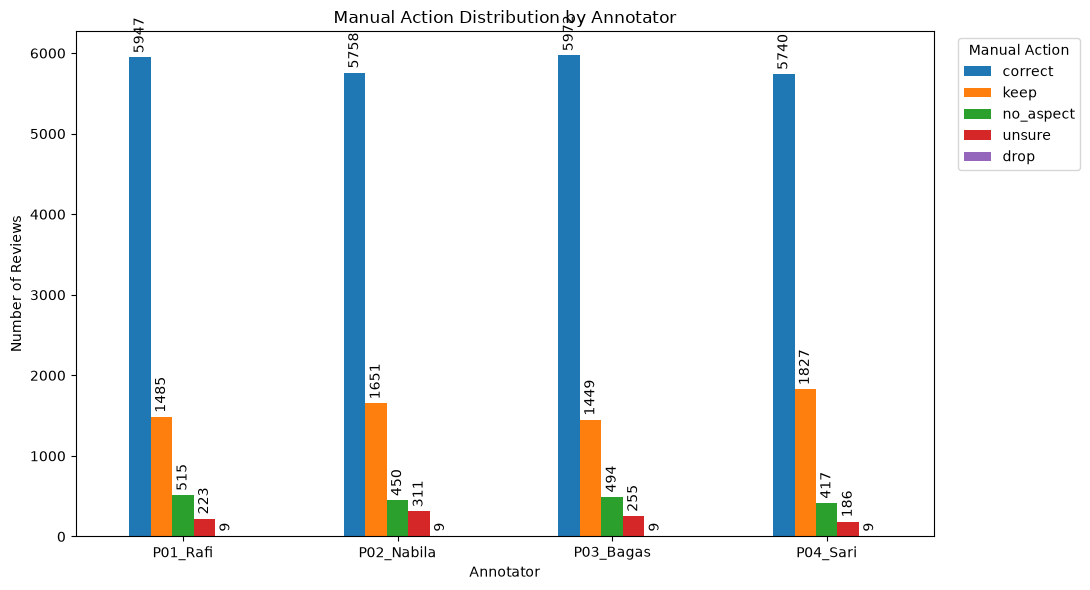

Saved: human_verification_inspection_output\figures\fig01_manual_action_distribution_by_annotator.png


In [ ]:
# ============================================================
# Visualization 1: annotator manual action distribution
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))
action_distribution_by_annotator.T.plot(kind="bar", ax=ax)
ax.set_title("Manual Action Distribution by Annotator")
ax.set_xlabel("Annotator")
ax.set_ylabel("Number of Reviews")
ax.tick_params(axis="x", labelrotation=0)
ax.legend(title="Manual Action", bbox_to_anchor=(1.02, 1), loc="upper left")
add_value_labels(ax, rotation=90)
save_current_fig("fig01_manual_action_distribution_by_annotator.png")

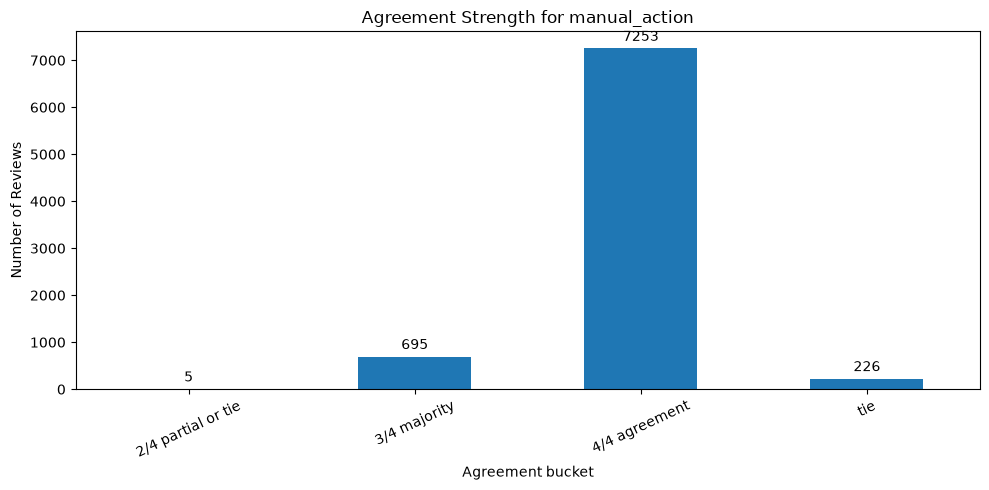

Saved: human_verification_inspection_output\figures\fig02_action_vote_agreement_strength.png


In [ ]:
# ============================================================
# Visualization 2: action voting agreement strength
# ============================================================

action_agreement_series = agreement_df["action_agreement_bucket"].value_counts().sort_index()
plot_bar(
    action_agreement_series,
    "Agreement Strength for manual_action",
    "Agreement bucket",
    "Number of Reviews",
    "fig02_action_vote_agreement_strength.png",
    figsize=(10, 5),
    rotation=25,
)

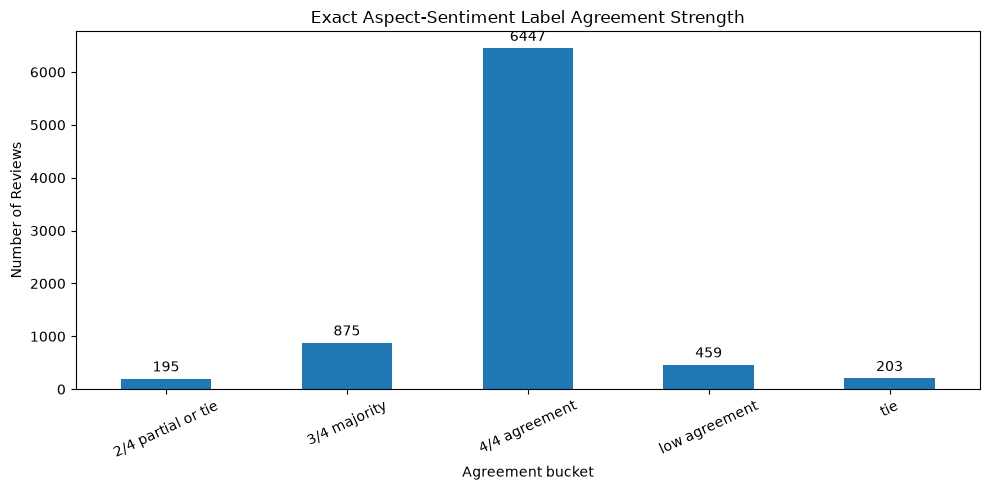

Saved: human_verification_inspection_output\figures\fig03_exact_label_agreement_strength.png


In [ ]:
# ============================================================
# Visualization 3: exact label agreement strength
# ============================================================

exact_label_agreement_series = agreement_df["exact_label_agreement_bucket"].value_counts().sort_index()
plot_bar(
    exact_label_agreement_series,
    "Exact Aspect-Sentiment Label Agreement Strength",
    "Agreement bucket",
    "Number of Reviews",
    "fig03_exact_label_agreement_strength.png",
    figsize=(10, 5),
    rotation=25,
)

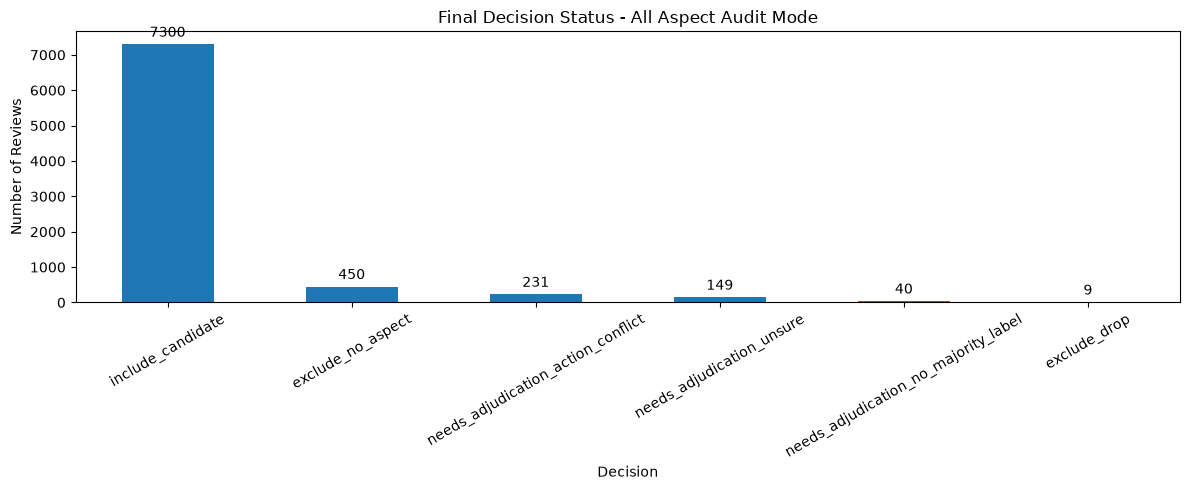

Saved: human_verification_inspection_output\figures\fig04_final_decision_status_all_aspects_audit_only.png


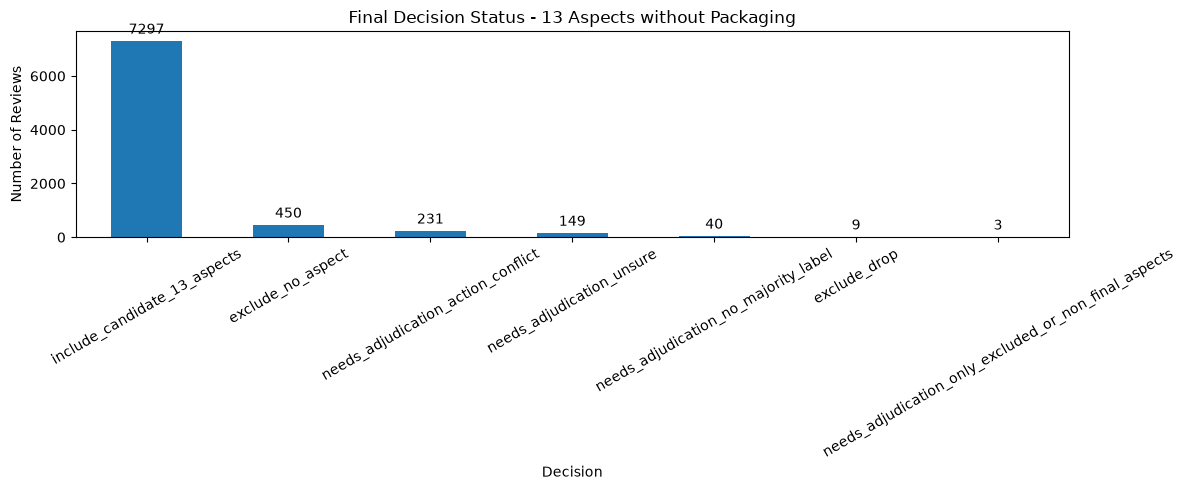

Saved: human_verification_inspection_output\figures\fig05_final_decision_status_13_aspects_no_packaging.png


In [ ]:
# ============================================================
# Visualization 4: final dataset decision status
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))
final_decision_summary_all.set_index("decision")["rows"].plot(kind="bar", ax=ax)
ax.set_title("Final Decision Status - All Aspect Audit Mode")
ax.set_xlabel("Decision")
ax.set_ylabel("Number of Reviews")
ax.tick_params(axis="x", labelrotation=30)
add_value_labels(ax)
save_current_fig("fig04_final_decision_status_all_aspects_audit_only.png")

fig, ax = plt.subplots(figsize=(12, 5))
final_decision_summary_13.set_index("decision")["rows"].plot(kind="bar", ax=ax)
ax.set_title("Final Decision Status - 13 Aspects without Packaging")
ax.set_xlabel("Decision")
ax.set_ylabel("Number of Reviews")
ax.tick_params(axis="x", labelrotation=30)
add_value_labels(ax)
save_current_fig("fig05_final_decision_status_13_aspects_no_packaging.png")


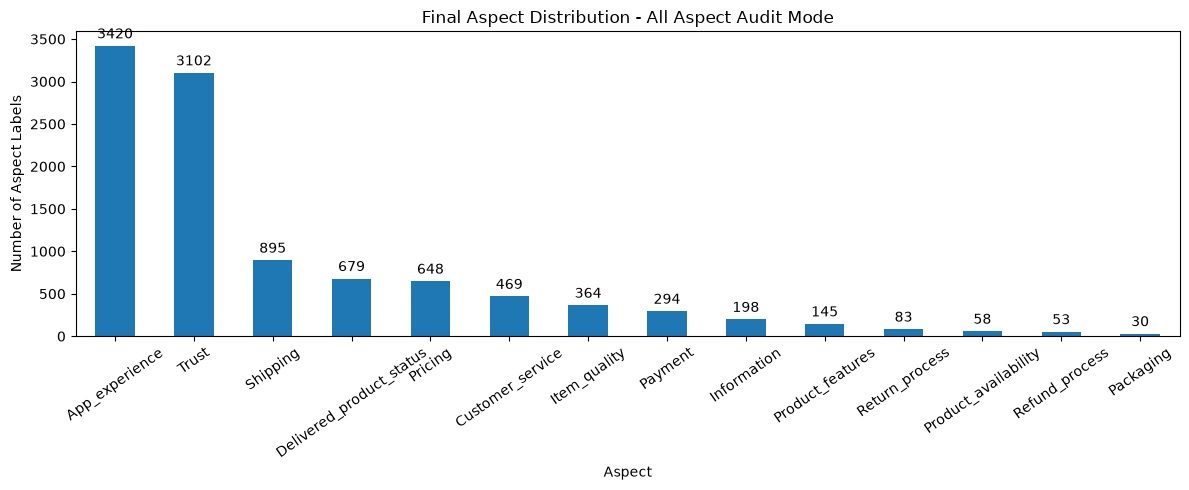

Saved: human_verification_inspection_output\figures\fig06_final_aspect_distribution_all_aspects_audit_only.png


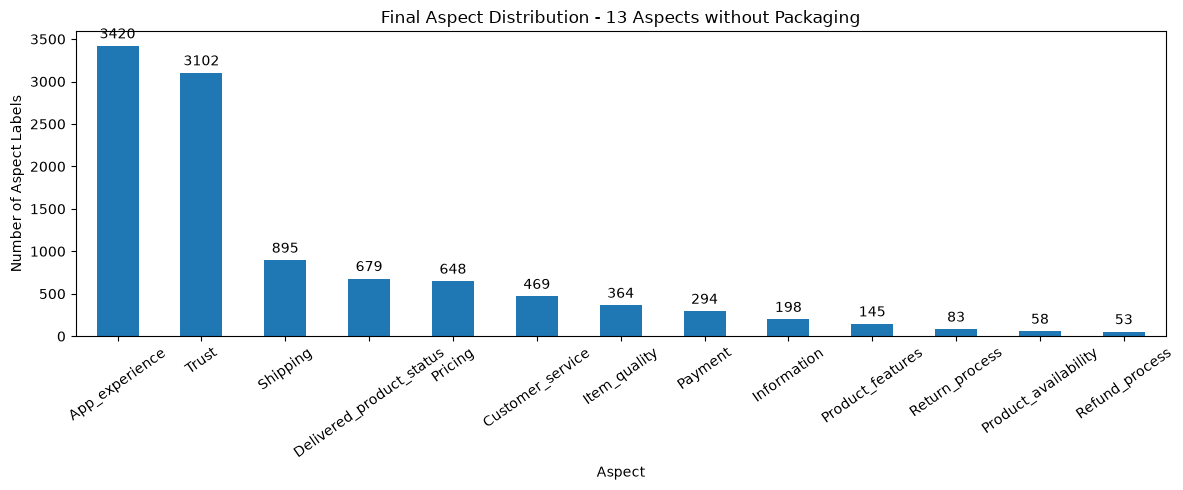

Saved: human_verification_inspection_output\figures\fig07_final_aspect_distribution_13_aspects_no_packaging.png


In [ ]:
# ============================================================
# Visualization 5: final aspect distribution
# ============================================================

if len(final_pairs_all_long) > 0:
    aspect_counts_all = final_pairs_all_long["aspect"].value_counts()
    plot_bar(
        aspect_counts_all,
        "Final Aspect Distribution - All Aspect Audit Mode",
        "Aspect",
        "Number of Aspect Labels",
        "fig06_final_aspect_distribution_all_aspects_audit_only.png",
        figsize=(12, 5),
        rotation=35,
    )
else:
    print("No all-aspect final pairs available.")

if len(final_pairs_13_long) > 0:
    aspect_counts_13 = final_pairs_13_long["aspect"].value_counts()
    plot_bar(
        aspect_counts_13,
        "Final Aspect Distribution - 13 Aspects without Packaging",
        "Aspect",
        "Number of Aspect Labels",
        "fig07_final_aspect_distribution_13_aspects_no_packaging.png",
        figsize=(12, 5),
        rotation=35,
    )
else:
    print("No final 13-aspect pairs available.")


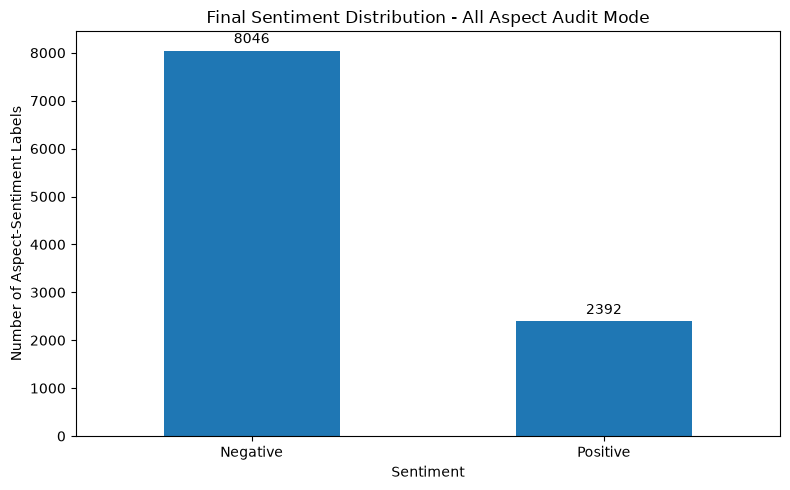

Saved: human_verification_inspection_output\figures\fig08_final_sentiment_distribution_all_aspects_audit_only.png


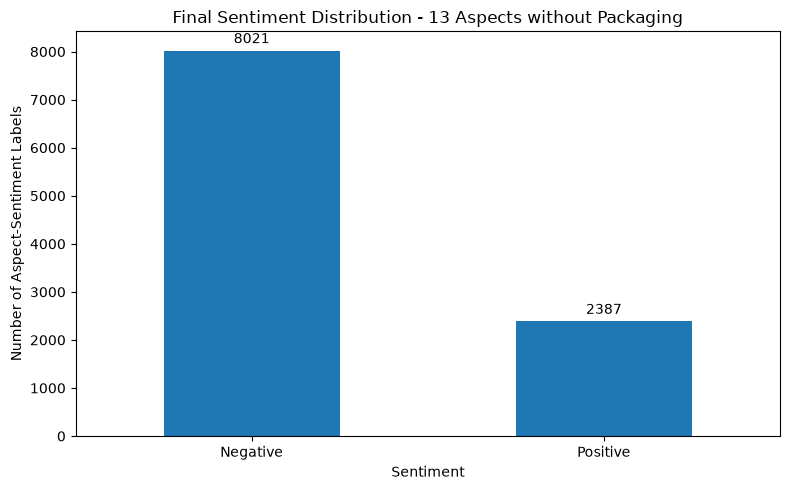

Saved: human_verification_inspection_output\figures\fig09_final_sentiment_distribution_13_aspects_no_packaging.png


In [ ]:
# ============================================================
# Visualization 6: final sentiment distribution
# ============================================================

if len(final_pairs_all_long) > 0:
    sentiment_counts_all = final_pairs_all_long["sentiment"].value_counts()
    plot_bar(
        sentiment_counts_all,
        "Final Sentiment Distribution - All Aspect Audit Mode",
        "Sentiment",
        "Number of Aspect-Sentiment Labels",
        "fig08_final_sentiment_distribution_all_aspects_audit_only.png",
        figsize=(8, 5),
        rotation=0,
    )

if len(final_pairs_13_long) > 0:
    sentiment_counts_13 = final_pairs_13_long["sentiment"].value_counts()
    plot_bar(
        sentiment_counts_13,
        "Final Sentiment Distribution - 13 Aspects without Packaging",
        "Sentiment",
        "Number of Aspect-Sentiment Labels",
        "fig09_final_sentiment_distribution_13_aspects_no_packaging.png",
        figsize=(8, 5),
        rotation=0,
    )


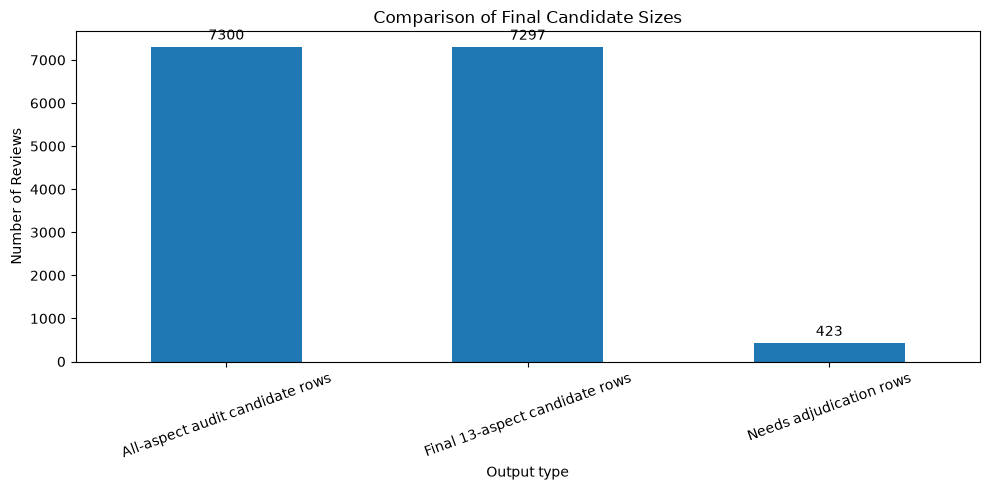

Saved: human_verification_inspection_output\figures\fig10_candidate_size_comparison_13_aspects.png


In [ ]:
# ============================================================
# Visualization 7: all-aspect vs final 13-aspect candidate count
# ============================================================

comparison_counts = pd.Series({
    "All-aspect audit candidate rows": len(candidate_all),
    "Final 13-aspect candidate rows": len(candidate_13),
    "Needs adjudication rows": len(adjudication_export),
})

plot_bar(
    comparison_counts,
    "Comparison of Final Candidate Sizes",
    "Output type",
    "Number of Reviews",
    "fig10_candidate_size_comparison_13_aspects.png",
    figsize=(10, 5),
    rotation=20,
)


sentiment,Negative,Positive
aspect,,
App_experience,3157,263
Customer_service,270,199
Delivered_product_status,525,154
Information,173,25
Item_quality,246,118
Packaging,25,5
Payment,260,34
Pricing,284,364
Product_availability,34,24


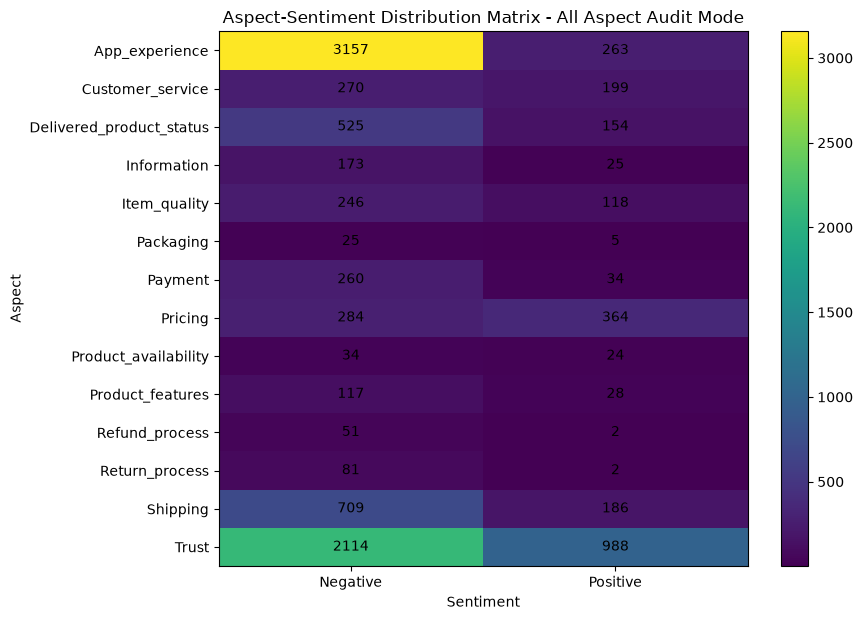

Saved: human_verification_inspection_output\figures\fig11_aspect_sentiment_matrix_all_aspects_audit_only.png


sentiment,Negative,Positive
aspect,,
App_experience,3157,263
Customer_service,270,199
Delivered_product_status,525,154
Information,173,25
Item_quality,246,118
Payment,260,34
Pricing,284,364
Product_availability,34,24
Product_features,117,28


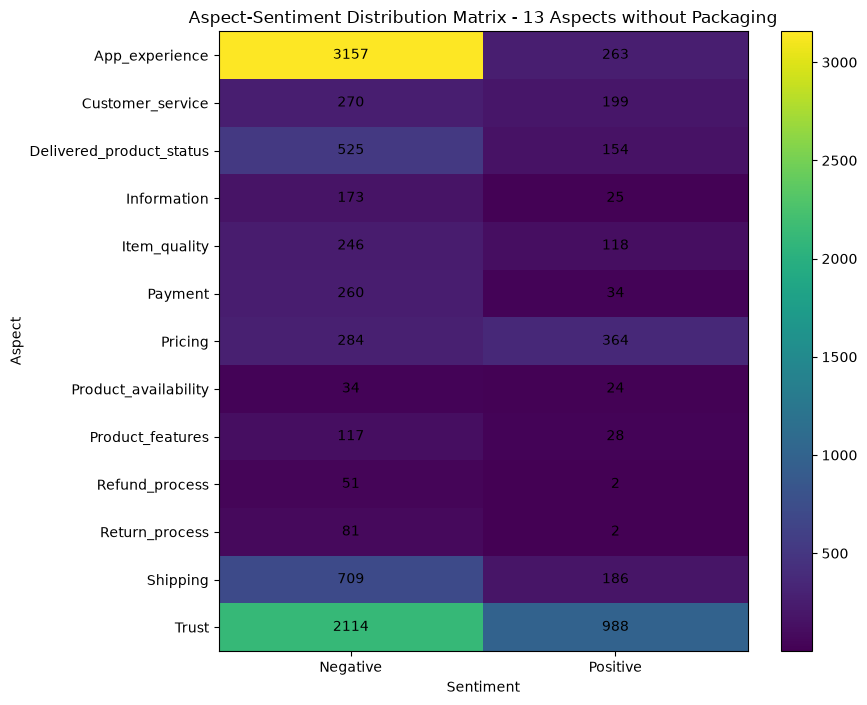

Saved: human_verification_inspection_output\figures\fig12_aspect_sentiment_matrix_13_aspects_no_packaging.png


In [ ]:
# ============================================================
# Visualization 8: aspect-sentiment distribution matrix
# ============================================================

if len(final_pairs_all_long) > 0:
    matrix_all = pd.crosstab(final_pairs_all_long["aspect"], final_pairs_all_long["sentiment"])
    display(matrix_all)

    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(matrix_all))))
    im = ax.imshow(matrix_all.values, aspect="auto")
    ax.set_title("Aspect-Sentiment Distribution Matrix - All Aspect Audit Mode")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Aspect")
    ax.set_xticks(np.arange(len(matrix_all.columns)))
    ax.set_xticklabels(matrix_all.columns)
    ax.set_yticks(np.arange(len(matrix_all.index)))
    ax.set_yticklabels(matrix_all.index)

    for i in range(matrix_all.shape[0]):
        for j in range(matrix_all.shape[1]):
            ax.text(j, i, int(matrix_all.iloc[i, j]), ha="center", va="center")

    fig.colorbar(im, ax=ax)
    save_current_fig("fig11_aspect_sentiment_matrix_all_aspects_audit_only.png")

if len(final_pairs_13_long) > 0:
    matrix_13 = pd.crosstab(final_pairs_13_long["aspect"], final_pairs_13_long["sentiment"])
    display(matrix_13)

    fig, ax = plt.subplots(figsize=(9, max(4, 0.55 * len(matrix_13))))
    im = ax.imshow(matrix_13.values, aspect="auto")
    ax.set_title("Aspect-Sentiment Distribution Matrix - 13 Aspects without Packaging")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Aspect")
    ax.set_xticks(np.arange(len(matrix_13.columns)))
    ax.set_xticklabels(matrix_13.columns)
    ax.set_yticks(np.arange(len(matrix_13.index)))
    ax.set_yticklabels(matrix_13.index)

    for i in range(matrix_13.shape[0]):
        for j in range(matrix_13.shape[1]):
            ax.text(j, i, int(matrix_13.iloc[i, j]), ha="center", va="center")

    fig.colorbar(im, ax=ax)
    save_current_fig("fig12_aspect_sentiment_matrix_13_aspects_no_packaging.png")


In [21]:
# ============================================================
# 18. Thesis-ready summary text generator
# ============================================================

summary_text = f"""
Human verification was conducted by four annotators on {n_rows:,} review rows. The final verified dataset was constructed using majority voting. For the row-level action label, the selected action was accepted when at least {MAJORITY_THRESHOLD} out of 4 annotators agreed. For ABSA labels, voting was performed at the aspect-sentiment pair level, where each Aspect:Sentiment pair was accepted if it received at least {MAJORITY_THRESHOLD} votes. This pair-level strategy was used because a single review can contain multiple aspects. After majority voting, the final thesis scope was applied by retaining only the 13 official aspects: {", ".join(FINAL_ASPECTS)}. The Packaging aspect was excluded from the final training dataset and stored only in the audit output when it appeared as a majority-voted pair. Rows without a clear majority, rows marked as unsure, rows with conflicting annotations, or rows that only contained excluded/non-final aspects were separated into an adjudication file for final researcher review.

Summary results:
- Total inspected rows: {n_rows:,}
- Rows with automatic final candidate labels, all-aspect audit mode: {len(candidate_all):,}
- Rows with automatic final candidate labels, 13-aspect no-Packaging mode: {len(candidate_13):,}
- Rows requiring adjudication in 13-aspect mode: {len(adjudication_export):,}
- Rows with majority-voted Packaging removed: {int(agreement_df["has_removed_packaging"].sum()):,}
""".strip()

print(summary_text)

with open(OUTPUT_DIR / "10_thesis_ready_method_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary_text)

print("Saved:", OUTPUT_DIR / "10_thesis_ready_method_summary.txt")


Human verification was conducted by four annotators on 8,179 review rows. The final verified dataset was constructed using majority voting. For the row-level action label, the selected action was accepted when at least 3 out of 4 annotators agreed. For ABSA labels, voting was performed at the aspect-sentiment pair level, where each Aspect:Sentiment pair was accepted if it received at least 3 votes. This pair-level strategy was used because a single review can contain multiple aspects. After majority voting, the final thesis scope was applied by retaining only the 13 official aspects: Information, Product_features, Item_quality, App_experience, Pricing, Product_availability, Payment, Delivered_product_status, Shipping, Return_process, Refund_process, Customer_service, Trust. The Packaging aspect was excluded from the final training dataset and stored only in the audit output when it appeared as a majority-voted pair. Rows without a clear majority, rows marked as unsure, rows with confli

In [22]:
# ============================================================
# 19. Final output checklist
# ============================================================

print("Main output files:")
for p in sorted(OUTPUT_DIR.glob("*.csv")):
    print("CSV:", p)
for p in sorted(OUTPUT_DIR.glob("*.xlsx")):
    print("XLSX:", p)
for p in sorted(OUTPUT_DIR.glob("*.txt")):
    print("TXT:", p)

print("\nFigure files:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("PNG:", p)

Main output files:
CSV: human_verification_inspection_output\01_annotator_wide_comparison.csv
CSV: human_verification_inspection_output\02_row_level_agreement.csv
CSV: human_verification_inspection_output\03_pair_level_votes_long.csv
CSV: human_verification_inspection_output\04_needs_adjudication_rows_13_aspects.csv
CSV: human_verification_inspection_output\04b_removed_non_final_aspect_pairs_audit.csv
CSV: human_verification_inspection_output\05_final_candidate_all_aspects_audit_only.csv
CSV: human_verification_inspection_output\06_final_candidate_13_aspects_no_packaging.csv
CSV: human_verification_inspection_output\06_final_candidate_focused_aspects.csv
CSV: human_verification_inspection_output\08_final_pairs_all_aspects_long_audit_only.csv
CSV: human_verification_inspection_output\09_final_pairs_13_aspects_no_packaging_long.csv
XLSX: human_verification_inspection_output\07_human_verification_summary_tables.xlsx
TXT: human_verification_inspection_output\10_thesis_ready_method_summary.